# Matbench bandgap: controlled model comparison

Compare XGBoost, CatBoost, and Extra Trees using identical feature sets and official nested evaluation. Twenty configurations per family are reused across three feature sets. Each outer fold selects independently by inner MAE. No early stopping or ensembles are used.

This follows earlier dataset exploration; outer test scores are revealed only after all five models are frozen. Prior results are retained as benchmark development history. Do not change the method in response to this run’s test results.

In [1]:
from pathlib import Path
import json, hashlib, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matbench.bench import MatbenchBenchmark
from matminer.featurizers.composition import ElementProperty, ElementFraction, Stoichiometry, ValenceOrbital
from elementembeddings.composition import composition_featuriser
from pymatgen.core import Composition
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.ensemble import ExtraTreesRegressor
import time

SEED = 42
OUT = Path('results/model-comparison')
OUT.mkdir(parents=True, exist_ok=True)
mb = MatbenchBenchmark(autoload=False, subset=['matbench_expt_gap'])
task = next(iter(mb.tasks))
task.load()


2026-11-13 16:29:47 INFO     Initialized benchmark 'matbench_v0.1' with 1 tasks: 
['matbench_expt_gap']


2026-11-13 16:29:47 INFO     Loading dataset 'matbench_expt_gap'...


2026-11-13 16:29:47 INFO     Dataset 'matbench_expt_gap loaded.


## Composition representations

Feature lookup is deterministic and does not use targets. Learned imputation and constant-column removal are fitted within each training fold. Full Magpie statistics capture extrema and spread; element fractions and stoichiometry retain additional composition information.

In [2]:
FEATURES = ['mean_variance', 'magpie', 'magpie_composition']
def features(inputs, kind):
    if kind == 'mean_variance':
        frame = pd.DataFrame({'composition': list(inputs)})
        values = composition_featuriser(frame, formula_column='composition', embedding='magpie', stats=['mean', 'variance'])
        return values.drop(columns='composition').to_numpy(dtype=float)
    featurizers = [ElementProperty.from_preset('magpie')]
    if kind == 'magpie_composition':
        featurizers += [ElementFraction(), Stoichiometry(), ValenceOrbital()]
    return np.asarray([[v for f in featurizers for v in f.featurize(Composition(s))] for s in inputs], dtype=float)

def pipeline(params, family='xgboost'):
    if family == 'xgboost':
        estimator = XGBRegressor(random_state=SEED, n_jobs=4, **params)
    elif family == 'catboost':
        estimator = CatBoostRegressor(random_seed=SEED, thread_count=4, verbose=False,
                                      allow_writing_files=False, **params)
    else:
        estimator = ExtraTreesRegressor(random_state=SEED, n_jobs=4, **params)
    return make_pipeline(SimpleImputer(strategy='median', keep_empty_features=True),
                         VarianceThreshold(), estimator)

rng = np.random.default_rng(SEED)
previous = json.loads(Path('results/mae/protocol.json').read_text())['selections']['0']['params']
settings = []
for i in range(10):
    if i == 0:
        params = {k:v for k,v in previous.items() if k != 'objective'}
    else:
        nearby = i < 5
        params = dict(max_depth=int(rng.integers(5,10) if nearby else rng.integers(2,11)),
            learning_rate=float(np.exp(rng.uniform(np.log(.015 if nearby else .01),np.log(.06 if nearby else .2)))),
            n_estimators=int(rng.integers(500 if nearby else 300,1501)),
            min_child_weight=int(rng.integers(1,11 if nearby else 21)),
            subsample=float(rng.uniform(.6,1)), colsample_bytree=float(rng.uniform(.6,1)),
            reg_alpha=float(10**rng.uniform(-4,1)),reg_lambda=float(10**rng.uniform(-2,2)))
    for loss in ['reg:squarederror','reg:absoluteerror']:
        settings.append(dict(family='xgboost', setting=f'xgb_{i}_{loss}', params=dict(params,objective=loss)))
for i in range(10):
    params=dict(depth=int(rng.integers(4,11)),iterations=int(rng.integers(300,1501)),
        learning_rate=float(10**rng.uniform(-2,np.log10(.2))),l2_leaf_reg=float(10**rng.uniform(-1,2)))
    for loss in ['RMSE','MAE']:
        settings.append(dict(family='catboost',setting=f'cat_{i}_{loss}',params=dict(params,loss_function=loss)))
for i in range(20):
    settings.append(dict(family='extra_trees',setting=f'extra_{i}',params=dict(
        criterion='squared_error',n_estimators=int(rng.integers(300,801)),
        max_depth=[10,20,40,None][int(rng.integers(4))],min_samples_leaf=int(rng.integers(1,11)),
        max_features=float(rng.choice([.3,.6,1.])))))
candidates = [dict(**s,features=kind) for s in settings for kind in FEATURES]
assert len(candidates) == 180
for setting in settings:
    assert {v['features'] for v in candidates if v['setting']==setting['setting']} == set(FEATURES)
protocol = dict(seed=SEED, inner_folds=3, candidates=candidates)
protocol_hash = hashlib.sha256(json.dumps(protocol,sort_keys=True).encode()).hexdigest()
print('Fixed protocol:',protocol_hash,'| candidates per outer fold:',len(candidates))


Fixed protocol: b72b5c311416d89b6f12ba352b546bd31ff0093628b5959f29d5cc1f8ee8c154 | candidates per outer fold: 180


## Training-only smoke check

No test inputs or targets are accessed here.

In [3]:
train_inputs, train_targets = task.get_train_and_val_data(task.folds[0])
a = features(train_inputs.iloc[:40], 'magpie_composition')
for family, params in [('xgboost',dict(n_estimators=2,max_depth=2)),
        ('catboost',dict(iterations=2,depth=2,loss_function='MAE')),
        ('extra_trees',dict(n_estimators=2,max_depth=2))]:
    smoke = pipeline(params, family)
    smoke.fit(a[:30], train_targets.iloc[:30])
    assert np.isfinite(smoke.predict(a[30:])).all()
print('All three training-only estimator smoke checks passed')


All three training-only estimator smoke checks passed


/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)
/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/featurizers/composition/orbital.py:115: UserWarning: ValenceOrbital(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
     

## Inner validation and independent outer-fold refits

The median baseline and original fixed XGBoost configuration are references. Select only by inner MAE; identical inner splits are used for every candidate. This quick search uses 2,700 candidate fits plus baselines and refits. It is not guaranteed to improve on previous results.

In [4]:
frozen = {}
rows = []
coverage = []
for fold in task.folds:
    inputs, y = task.get_train_and_val_data(fold)
    split = task.validation[task.folds_map[fold]]
    train_ids, test_ids = set(split.train), set(split.test)
    assert train_ids.isdisjoint(test_ids)
    coverage.extend(split.test)
    cv = list(KFold(3, shuffle=True, random_state=SEED).split(inputs))
    for tr, va in cv:
        assert set(tr).isdisjoint(va)
        assert len(tr) + len(va) == len(inputs)
    matrices = {kind: features(inputs, kind) for kind in FEATURES}
    for name, estimator in [('median', DummyRegressor(strategy='median')),
            ('original_xgb', pipeline(dict(n_estimators=100, max_depth=3, objective='reg:squarederror')))]:
        scores = -cross_val_score(estimator, matrices['mean_variance'], y, cv=cv,
                                  scoring='neg_mean_absolute_error', n_jobs=1)
        rows.append(dict(fold=fold, candidate=name, inner_mae=float(scores.mean())))
    trials = []
    for i, candidate in enumerate(candidates):
        started = time.perf_counter()
        scores = -cross_val_score(pipeline(candidate['params'], candidate['family']), matrices[candidate['features']], y,
                                 cv=cv, scoring='neg_mean_absolute_error', n_jobs=1)
        score = float(scores.mean())
        assert np.isfinite(score)
        trials.append(score)
        rows.append(dict(fold=fold, candidate=i, setting=candidate['setting'], family=candidate['family'], features=candidate['features'], inner_mae=score, fold_maes=scores.tolist(), seconds=time.perf_counter()-started))
        pd.DataFrame(rows).to_csv(OUT / 'inner_validation.csv', index=False)
        if i % 15 == 0: print(f'Outer fold {fold}, candidate {i}/{len(candidates)}', flush=True)
    winner = int(np.argmin(trials))
    choice = candidates[winner]
    model = pipeline(choice['params'], choice['family']).fit(matrices[choice['features']], y)
    frozen[fold] = dict(model=model, choice=choice, inner_mae=trials[winner],
                        columns=matrices[choice['features']].shape[1])
    joblib.dump(frozen[fold], OUT / f'fold_{fold}.joblib')
    print('Completed training fold', fold, '| selected inner MAE', trials[winner])
assert len(coverage) == len(set(coverage)) == len(task.df)
assert set(coverage) == set(task.df.index)
pd.DataFrame(rows).to_csv(OUT / 'inner_validation.csv', index=False)
(OUT / 'protocol.json').write_text(json.dumps(dict(**protocol, sha256=protocol_hash,
    selections={str(f): v['choice'] for f,v in frozen.items()}), indent=2))
assert len(frozen) == 5
print('All five models frozen. No outer test scores have been inspected.')


Featurising compositions...


  0%|          | 0/3683 [00:00<?, ?it/s]

  6%|▋         | 239/3683 [00:00<00:01, 2389.63it/s]

 13%|█▎        | 488/3683 [00:00<00:01, 2448.11it/s]

 20%|█▉        | 733/3683 [00:00<00:01, 2417.89it/s]

 27%|██▋       | 981/3683 [00:00<00:01, 2440.68it/s]

... (166 outputs left out)

Outer fold 4, candidate 135/180


Outer fold 4, candidate 150/180


Outer fold 4, candidate 165/180


Completed training fold 4 | selected inner MAE 0.4161533264653732
All five models frozen. No outer test scores have been inspected.


## Visual comparison of model families

![Selected validation MAE by model family](results/model-comparison/model-comparison.png)

Each model family was given 20 configurations evaluated across three feature sets. Points show its best mean inner-validation MAE for each outer fold. Feature and hyperparameter selection make these validation scores optimistic; they are not test scores. The final test section evaluates only the winner selected independently for each outer fold, rather than evaluating every family on the test sets.


## Final evaluation — run after all models are frozen

This is the only section that scores outer test predictions. Do not change the method in response to these results. The leaderboard statistic is the unweighted mean of five test MAEs, not the inner tuning score.

In [5]:
test_predictions = {}
for fold in task.folds:
    entry = frozen[fold]
    inputs = task.get_test_data(fold, include_target=False)
    X = features(inputs, entry['choice']['features'])
    assert X.shape[1] == entry['columns']
    pred = entry['model'].predict(X)
    assert len(pred) == len(inputs) and np.isfinite(pred).all()
    test_predictions[fold] = pred
# Only after every prediction is fixed, reveal scores.
for fold in task.folds:
    task.record(fold, test_predictions[fold], params=frozen[fold]['choice'])
mb.to_file(str(OUT / 'matbench_results.json.gz'))
summary = pd.DataFrame([dict(fold=f, **task.results[task.folds_map[f]].scores) for f in task.folds])
display(summary)
print('Test MAE mean:', summary.mae.mean(), 'eV; population SD:', summary.mae.std(ddof=0))
summary.to_csv(OUT / 'test_scores.csv', index=False)


/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)
/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/featurizers/composition/orbital.py:115: UserWarning: ValenceOrbital(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
     

/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)
/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/featurizers/composition/orbital.py:115: UserWarning: ValenceOrbital(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
     

/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)
/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/featurizers/composition/orbital.py:115: UserWarning: ValenceOrbital(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
     

/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)
/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/featurizers/composition/orbital.py:115: UserWarning: ValenceOrbital(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
     

/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/utils/data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)
/Users/nick/Code/materials-ml/MatBenchExperiments/.venv/lib/python3.12/site-packages/matminer/featurizers/composition/orbital.py:115: UserWarning: ValenceOrbital(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
     

2026-11-13 18:21:26 INFO     Recorded fold matbench_expt_gap-0 successfully.


... (3 outputs left out)

2026-11-13 18:21:26 INFO     Recorded fold matbench_expt_gap-4 successfully.


2026-11-13 18:21:26 INFO     Successfully wrote MatbenchBenchmark to file 'results/model-comparison/matbench_results.json.gz'.


,fold,mae,rmse,mape,max_error
0,0,0.379323,0.710065,0.318465,5.517310
1,1,0.371053,0.719071,0.258085,5.611227
2,2,0.426944,0.859720,0.367405,8.818355
3,3,0.376218,0.726338,0.324321,4.835931
4,4,0.391004,0.753017,0.348984,5.965295


Test MAE mean: 0.38890835287234304 eV; population SD: 0.020114096515695342


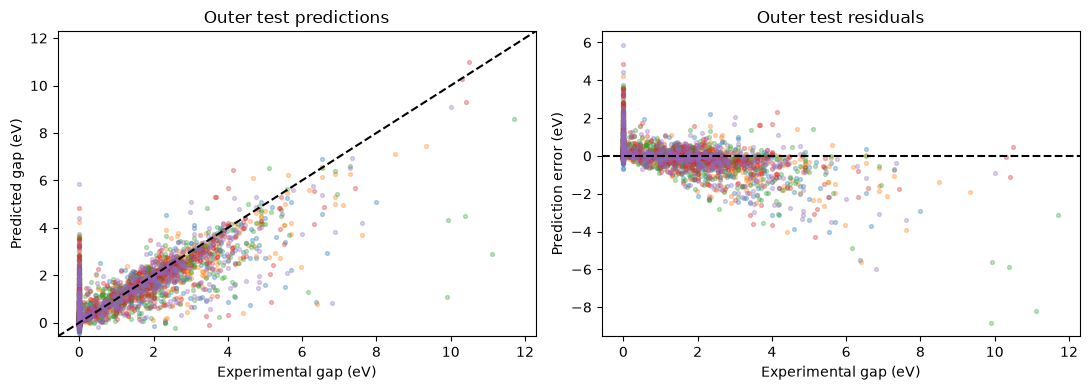

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for fold in task.folds:
    _, truth = task.get_test_data(fold, include_target=True)
    pred = test_predictions[fold]
    axes[0].scatter(truth, pred, s=8, alpha=.3)
    axes[1].scatter(truth, pred-np.asarray(truth), s=8, alpha=.3)
lo, hi = axes[0].get_xlim()
axes[0].plot([lo,hi],[lo,hi], 'k--')
axes[0].set(xlim=(lo,hi), ylim=(lo,hi), xlabel='Experimental gap (eV)', ylabel='Predicted gap (eV)', title='Outer test predictions')
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='Experimental gap (eV)', ylabel='Prediction error (eV)', title='Outer test residuals')
plt.tight_layout()
